In [2]:
import sys
sys.path.append('/home/nathan/thermo_flux')

import pandas as pd
import os
# Add the parent directory to sys.path
sys.path.append(os.path.abspath('../3_src/'))
# Now import Model from freeflux

import numpy as np

import seaborn as sns
import analysis.io_func as io_func
import matplotlib.pyplot as plt

from analysis import config_13c as config
import math

/home/nathan/PhD/04.Computational/202601_13C/3_src/freeflux/src/freeflux/core/reaction.py:104: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.substrates_info = pd.concat((self.substrates_info, newSubs))
/home/nathan/PhD/04.Computational/202601_13C/3_src/freeflux/src/freeflux/core/reaction.py:132: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.products_info = pd.concat((self.products_info, newPros))
/home/nathan/PhD/04.Computational/202601_13C/3_src/freeflux/src/freeflux/core/reaction.py:

## highligh a few reactions that dont go same direcitona s in yeast9

###  i first scan through rxn common to my yeast model and y9 in preivous notebook 4c1. 
then here plot for reactions that have different directions

In [3]:
# Import general configs:
palette ,cpalette,cfg=io_func.import_plotconfigs(cpalette=True)

In [4]:
condition='WT' 
model=config.model
bootstrap_flux_dfwt=config.bootstrap_flux_df(condition)#pd.read_csv(f'{config.DRAWNSAMPLES_FOLDER}/{condition}_drawn_samples.csv',index_col=0)


In [5]:
condition='TM6' 
model=config.model
bootstrap_flux_dftm6=config.bootstrap_flux_df(condition)#pd.read_csv(f'{config.DRAWNSAMPLES_FOLDER}/{condition}_drawn_samples.csv',index_col=0)


 load diff dir df and look at flux values for differing rxn

In [6]:
diff_dir = pd.read_csv(f'{config.FREEFLUXRUN_FOLDER}/df_bootstrap_compare_reaction_directions.csv',index_col=0)

In [16]:
diff_dir

,WT,TM6,Yeast9
ASNS1,Forward,Forward,Forward
ASPK,Forward,Forward,Forward
ASPTA,Backward,Backward,Reversible
ASPTAm,Reversible,Forward,Backward
ASAD,Forward,Forward,Forward
...,...,...,...
SUCCPItm-2-2,Backward,Backward,Forward
SUCFUMtm-2-2,Reversible,Reversible,Forward
THRtm+0,Forward,Forward,Reversible
biomass_ce,Forward,Forward,Reversible


In [8]:
def counts_diff(diff_dir, condition, return_index=True,only_wrong=True):
    # Select relevant columns
    diff_dir_cond = diff_dir[[condition, 'Yeast9']].copy()
    
    # Row-wise mask
    if only_wrong :
        mask = (
            (diff_dir_cond[condition] != diff_dir_cond['Yeast9']) &
            (diff_dir_cond[condition] != 'Reversible') &
            (diff_dir_cond['Yeast9'] != 'Reversible')
        )
    else:
        mask = (
            (diff_dir_cond[condition] != diff_dir_cond['Yeast9']) &
            (diff_dir_cond[condition] == 'Reversible')
        )

    
    if return_index:
        return diff_dir_cond.index[mask]
    else:
        return diff_dir_cond[mask]
    # return dfcount
index_wt_diff=counts_diff(diff_dir,'WT',only_wrong=False,return_index=True)
index_tm6_diff=counts_diff(diff_dir,'TM6',only_wrong=False,return_index=True)

In [17]:
diff_index=index_wt_diff.union(index_tm6_diff)
diff_index

Index(['ASPGLUtm-1-1', 'ASPTAm', 'DAK', 'GCY1', 'PItm-2+H', 'PYRtm-1+H',
       'SUCFUMtm-2-2'],
      dtype='object')

In [15]:
counts_diff(diff_dir,'TM6',only_wrong=True,return_index=False)

,TM6,Yeast9
ASPTAm,Forward,Backward
FTHFL,Backward,Forward
GLUDym,Backward,Forward
PHETA1,Backward,Forward
GLYCt+0,Forward,Backward
SO4t-2,Backward,Forward
2OXOADPAKGtm-2-2,Forward,Backward
AKGMALtm-2-2,Backward,Forward
ASPGLUtm-1-1,Forward,Backward
OAAtm-2,Backward,Forward


In [12]:
from scipy.stats import gaussian_kde

def plot_kde_bounded(ax,rid,full_flux_df,lb,ub,**kwargs):
    data = full_flux_df.loc[rid, ].values


    kde = gaussian_kde(data)

    x = np.linspace(lb, ub, 500)
    y = kde(x)

    # Force vertical drop at boundaries
    x_plot = np.concatenate(([lb], x, [ub]))
    y_plot = np.concatenate(([0], y, [0]))

    ax.plot(x_plot, y_plot,**kwargs)

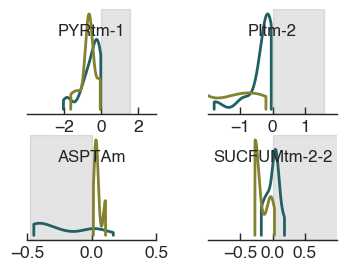

In [ ]:
rxn_list=['PYRtm-1','PItm-2','ASPTAm','SUCFUMtm-2-2']

nrows=2
ncols=math.ceil(len(rxn_list)/nrows)
fig,axes=plt.subplots(nrows,ncols,figsize=(4,3))
fig.subplots_adjust(wspace=0.4)
axes=axes.flatten()

io_func.scale_rcparams(fig,scalingf=0.5)

for rid in rxn_list:
    ax=axes[rxn_list.index(rid)]

    lbwt,ubwt = bootstrap_flux_dfwt.loc[rid].min(), bootstrap_flux_dfwt.loc[rid].max()
    lbtm6,ubtm6 = bootstrap_flux_dftm6.loc[rid].min(), bootstrap_flux_dftm6.loc[rid].max()

    # sns.kdeplot(bootstrap_flux_dfwt.loc[rid], ax=ax, cut=0)
    # sns.kdeplot(bootstrap_flux_dftm6.loc[rid], ax=ax, color=palette[2], cut=0)

    plot_kde_bounded(ax, rid, bootstrap_flux_dfwt, lbwt, ubwt, linewidth=2)
    plot_kde_bounded(
        ax, rid, bootstrap_flux_dftm6, lbtm6, ubtm6,
        linewidth=2, **{'color':palette[2]}
    )

    ax.set_ylabel('')
    ax.set_xlabel('')
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)

    # text rxn id at top of graph
    ax.text(0.5, 0.8, rid, transform=ax.transAxes,
            va='center', ha='center', fontsize=12)

    ### check yeast9 pred dir and fill between either 0,xmax or xmin,0
    # depending on if fwd or back.
    xmin, xmax = ax.get_xlim()

    direction = diff_dir.loc[rid, 'Yeast9']

    if direction == 'Forward':
        ax.axvspan(0, xmax+1.5, alpha=0.15, color='.3')
    elif direction == 'Backward':
        ax.axvspan(xmin, 0, alpha=0.15, color='.3')

    # io_func.rescale_axlim(ax,nbins=3,how='x')
    ## change xticks to set ceil of ticks
    # ax.set_xticks([math.ceil(x) for x in ax.get_xticks()])

axes[0].set_xlim(-4,3)
axes[0].set_xticks([-2,0,2])

axes[1].set_xlim(-2,2)
axes[1].set_xticks([-1,0,1])

axes[2].set_xlim(-0.5,0.5)
axes[2].set_xticks([-0.5,0,0.5])

axes[3].set_xlim(-1,1)
axes[3].set_xticks([-0.5,0,0.5])

## savefig
# plt.savefig(f'{config.SUPP_PLOTS_FOLDER}/SuppFig_kderxn_wrong_predefineddir.png',
#             bbox_inches='tight',dpi=300)
# plt.savefig(f'{config.SUPP_PLOTS_FOLDER}/SuppFig_kderxn_wrong_predefineddir.svg',
#             bbox_inches='tight',dpi=300)